# Smart Battery Manager - TinyML
**IoT Project 2026** - Dario Falaschi & Leonardo Lentini


### 1. Data Loading and Preparation
*Remember to upload the `Plant_1_Generation_Data.csv`, `Plant_1_Weather_Sensor_Data.csv`, `Plant_2_Generation_Data.csv`, and `Plant_2_Weather_Sensor_Data.csv` files to the file panel on the left.*

In [49]:
import pandas as pd
import numpy as np

# --- PLANT 1 PROCESSING ---
df_gen_1 = pd.read_csv('Plant_1_Generation_Data.csv')
df_weather_1 = pd.read_csv('Plant_1_Weather_Sensor_Data.csv')

# Plant 1 uses a specific date format
df_gen_1['DATE_TIME'] = pd.to_datetime(df_gen_1['DATE_TIME'], format='%d-%m-%Y %H:%M')
df_weather_1['DATE_TIME'] = pd.to_datetime(df_weather_1['DATE_TIME'])

# Filter by a single inverter to maintain a coherent time-series
inverter_id_1 = df_gen_1['SOURCE_KEY'].unique()[0]
df_gen_filtered_1 = df_gen_1[df_gen_1['SOURCE_KEY'] == inverter_id_1].copy()

# Merge generation and weather data
df_merged_1 = pd.merge(df_gen_filtered_1, df_weather_1, on='DATE_TIME', how='inner')
target_columns = ['DATE_TIME', 'AC_POWER', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
df_1 = df_merged_1[target_columns].sort_values('DATE_TIME').reset_index(drop=True)


# --- PLANT 2 PROCESSING ---
df_gen_2 = pd.read_csv('Plant_2_Generation_Data.csv')
df_weather_2 = pd.read_csv('Plant_2_Weather_Sensor_Data.csv')

# Plant 2 uses a different date format (usually Year-Month-Day)
df_gen_2['DATE_TIME'] = pd.to_datetime(df_gen_2['DATE_TIME'])
df_weather_2['DATE_TIME'] = pd.to_datetime(df_weather_2['DATE_TIME'])

# Filter by a single inverter
inverter_id_2 = df_gen_2['SOURCE_KEY'].unique()[0]
df_gen_filtered_2 = df_gen_2[df_gen_2['SOURCE_KEY'] == inverter_id_2].copy()

# Merge generation and weather data
df_merged_2 = pd.merge(df_gen_filtered_2, df_weather_2, on='DATE_TIME', how='inner')
df_2 = df_merged_2[target_columns].sort_values('DATE_TIME').reset_index(drop=True)


# --- MERGING THE TWO PLANTS ---
# Concatenate the two dataframes vertically to create a generalized dataset
df = pd.concat([df_1, df_2], ignore_index=True)

print(f"Plant 1 Rows: {len(df_1)}")
print(f"Plant 2 Rows: {len(df_2)}")
print(f"Total rows for training: {len(df)}")
df.head()

Plant 1 Rows: 3154
Plant 2 Rows: 3195
Total rows for training: 6349


,DATE_TIME,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,0.0,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,0.0,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,0.0,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,0.0,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,0.0,24.621525,22.165423,0.0


### 2. Feature Engineering (Temporal Logic and Target Variable)

In [50]:
# Create historical lag features (15 minutes ago)
df['AC_POWER_t-1'] = df['AC_POWER'].shift(1)
df['IRRADIATION_t-1'] = df['IRRADIATION'].shift(1)

# Create target variable (Power in 15 minutes)
df['AC_POWER_t+1'] = df['AC_POWER'].shift(-1)

# Hardware-Driven Threshold: ~10% of peak capacity
THRESHOLD = 140.0

# Label = 1 (Imminent Drop) IF current production is safe (>= 140W)
# BUT in the next 15 minutes it will drop below the vital hardware limit (< 140W)
df['Condition'] = np.where((df['AC_POWER'] >= THRESHOLD) & (df['AC_POWER_t+1'] < THRESHOLD), 1, 0)

# Drop NaNs generated by shifting and keep only model input columns
df = df.dropna()
df = df[['Condition', 'AC_POWER', 'AC_POWER_t-1', 'IRRADIATION', 'IRRADIATION_t-1', 'MODULE_TEMPERATURE']]

# Calculate and print the percentage of predictions
total_samples = len(df)
drop_events = df['Condition'].sum()
drop_percentage = (drop_events / total_samples) * 100

CLASS_NAMES = ['Stable', 'Imminent Drop']
print('Original Class Distribution:')
print(df['Condition'].value_counts())
print(f'\nPercentage of Imminent Drop events: {drop_percentage:.2f}% of the total dataset')
df.head()

Original Class Distribution:
Condition
0    6241
1     106
Name: count, dtype: int64

Percentage of Imminent Drop events: 1.67% of the total dataset


,Condition,AC_POWER,AC_POWER_t-1,IRRADIATION,IRRADIATION_t-1,MODULE_TEMPERATURE
1,0,0.0,0.0,0.0,0.0,22.761668
2,0,0.0,0.0,0.0,0.0,22.592306
3,0,0.0,0.0,0.0,0.0,22.360852
4,0,0.0,0.0,0.0,0.0,22.165423
5,0,0.0,0.0,0.0,0.0,21.968571


### 3. Train/Test Split

In [51]:
from sklearn.model_selection import train_test_split
import numpy as np

# Separate target and features
labels_1d = np.array(df.pop('Condition'))
features = np.array(df)

# 85% Train, 15% Test split
train_features, test_features, train_labels_1d, test_labels_1d = train_test_split(
    features, labels_1d, test_size=0.15, shuffle=True, random_state=42, stratify=labels_1d
)

### 4. Normalization
*We extract and print the scaling constants to paste directly into the Actuator's C firmware, ensuring the microcontroller applies the exact same mathematical transformation.*

In [52]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on training data to prevent Data Leakage
train_features = scaler.fit_transform(train_features)
test_features  = scaler.transform(test_features)

print('=== COPY THESE CONSTANTS INTO THE C FIRMWARE===')
print(f'static const float FEATURE_MEAN[5]  = ' \
      f'{{ {scaler.mean_[0]:.4f}f, {scaler.mean_[1]:.4f}f, {scaler.mean_[2]:.4f}f, {scaler.mean_[3]:.4f}f, {scaler.mean_[4]:.4f}f }};')
print(f'static const float FEATURE_SCALE[5] = ' \
      f'{{ {scaler.scale_[0]:.4f}f, {scaler.scale_[1]:.4f}f, {scaler.scale_[2]:.4f}f, {scaler.scale_[3]:.4f}f, {scaler.scale_[4]:.4f}f }};')
print('/* Order: AC_POWER, AC_POWER_t-1, IRRADIATION, IRRADIATION_t-1, MODULE_TEMPERATURE */')

=== COPY THESE CONSTANTS INTO THE C FIRMWARE===
static const float FEATURE_MEAN[5]  = { 277.4355f, 277.7913f, 0.2324f, 0.2329f, 32.0750f };
static const float FEATURE_SCALE[5] = { 380.5854f, 380.6051f, 0.3069f, 0.3076f, 11.8827f };
/* Order: AC_POWER, AC_POWER_t-1, IRRADIATION, IRRADIATION_t-1, MODULE_TEMPERATURE */


### 5. Class Balancing (Custom Weights)
*Power drop anomalies are extremely rare compared to normal operations.*

*We apply Custom Class Weights during training. This penalizes the model for missing drops while maintaining high precision on raw temporal data.*

In [53]:
from keras.utils import to_categorical

print("\nClass Distribution in Training:", np.bincount(train_labels_1d))

# Convert to One-Hot encoding for Keras compatibility
train_labels = to_categorical(train_labels_1d)
test_labels = to_categorical(test_labels_1d)

# Class 0 (Stable) is common, so we keep its weight low to prevent False Positives.
# Class 1 (Drop) is rare, so we boost its importance, but not too much to avoid paranoia.
custom_weights = {
    0: 1.0,
    1: 2.0  # A 2x multiplier (prevents widespread FPs while maintaining early warnings for drops)
}
print("Applied Class Weights:", custom_weights)


Class Distribution in Training: [5304   90]
Applied Class Weights: {0: 1.0, 1: 2.0}


### 6. Model Definition and Training
*We define a compact Neural Network. Early Stopping is implemented to halt training when validation loss stops improving, preventing overfitting and restoring the optimal weights.*

In [54]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input

NB_classes  = 2   # Stable (0) or Imminent Drop (1)
NB_features = 5   # Our 5 environmental/electrical features

model = tf.keras.Sequential([
    Input(shape=(NB_features,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(NB_classes, activation='softmax'),
])

# Slightly reduced learning rate for more stable convergence
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)

model.compile(optimizer=optimizer,
              loss=tf.keras.losses.categorical_crossentropy,
              metrics=['accuracy'])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 754 (2.95 KB)

 Trainable params: 754 (2.95 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=15,
                           restore_best_weights=True, verbose=1)

# Train using the native dataset and custom class weights
history = model.fit(
    x=train_features,
    y=train_labels,
    epochs=150,
    class_weight=custom_weights,
    validation_data=(test_features, test_labels),
    callbacks=[early_stop],
    verbose=1,
    shuffle=True
)

Epoch 1/150
169/169 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9564 - loss: 0.2883 - val_accuracy: 0.9832 - val_loss: 0.1111
Epoch 2/150
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9833 - loss: 0.1298 - val_accuracy: 0.9832 - val_loss: 0.0849
Epoch 3/150
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9833 - loss: 0.1212 - val_accuracy: 0.9832 - val_loss: 0.0794
Epoch 4/150
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9833 - loss: 0.1167 - val_accuracy: 0.9832 - val_loss: 0.0773
Epoch 5/150
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9833 - loss: 0.1122 - val_accuracy: 0.9832 - val_loss: 0.0756
Epoch 6/150
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9833 - loss: 0.1090 - val_accuracy: 0.9832 - val_loss: 0.0729
Epoch 7/150
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9833 - loss: 0.1059 - val_accuracy: 0.9832 - val_loss: 0.0705
Epoch 8/150
169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9833 - loss: 0.1038 - val_accu

### 7. Performance Evaluation and Visualization

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

=== OPTIMIZED CLASSIFICATION REPORT ===
               precision    recall  f1-score   support

       Stable       0.99      1.00      0.99       937
Imminent Drop       0.70      0.44      0.54        16

     accuracy                           0.99       953
    macro avg       0.85      0.72      0.77       953
 weighted avg       0.99      0.99      0.99       953



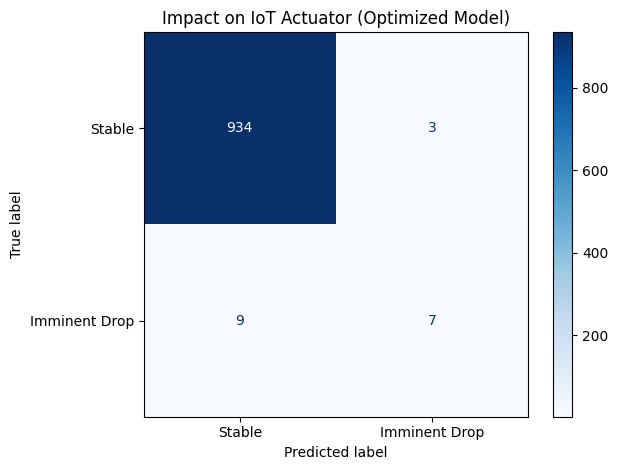

In [56]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred = model.predict(test_features).argmax(axis=1)
y_true = test_labels.argmax(axis=1)

print("\n=== OPTIMIZED CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=CLASS_NAMES,
    cmap='Blues'
)
plt.title('Impact on IoT Actuator (Optimized Model)')
plt.tight_layout()
plt.show()

### 8. Model Conversion for IoT using emlearn
*We convert our trained Keras neural network model into a pure C header file to integrate it directly into the Smart Actuator.*

In [57]:
!pip install emlearn

In [58]:
import emlearn
import os

path = 'smart_battery_model.h'

# Convert the Keras neural network into an inline .h file for the C compiler
cmodel = emlearn.convert(model, method='inline')
cmodel.save(file=path, name='smart_battery')

size_bytes = os.path.getsize(path)
nrf52840_ram = 256 * 1024  # bytes

print(f'Model saved to: {path}')
print(f'C file size: {size_bytes / 1024:.1f} KB ({size_bytes:,} bytes)')
print(f'Dongle RAM utilization: {size_bytes / nrf52840_ram * 100:.2f}%')

Model saved to: smart_battery_model.h
C file size: 9.9 KB (10,109 bytes)
Dongle RAM utilization: 3.86%


### 9. Dataset Export for Simulation Replay (Cooja)
*We isolate a 200-timestep window (50 hours) containing early warnings and a confirmed power drop event.*

*This chronological data is structured into a C header file (`dataset_replay.h`) to serve as a realistic simulation feed for our edge nodes in Cooja.*

In [60]:
import numpy as np
import pandas as pd

# 1. Predictions on the full timeline
features_cols = ['AC_POWER', 'AC_POWER_t-1', 'IRRADIATION', 'IRRADIATION_t-1', 'MODULE_TEMPERATURE']
X_full = scaler.transform(df[features_cols].values)
y_pred_full = model.predict(X_full).argmax(axis=1)

window_size = 200
plant_1_rows = 3154  # Prevents jumping across the two plants
target_local_tp_index = 10
selected_start = -1

# 3. Search for the OPTIMAL window (First TP exactly at local index 10)
for i in range(len(labels_1d) - window_size):

    if i < plant_1_rows < (i + window_size):
        continue

    w_labels = labels_1d[i : i + window_size]
    w_preds = y_pred_full[i : i + window_size]

    tp_indices = np.where((w_preds == 1) & (w_labels == 1))[0]
    fp_indices = np.where((w_preds == 1) & (w_labels == 0))[0]

    # Strict validation: We want a TP exactly at 10
    if len(tp_indices) > 0 and tp_indices[0] == target_local_tp_index:
        selected_start = i
        break

if selected_start != -1:
    start_step = selected_start
    end_step = start_step + window_size
    df_replay = df.iloc[start_step:end_step]

    final_labels = labels_1d[start_step:end_step]
    final_preds = y_pred_full[start_step:end_step]

    tp_locs = np.where((final_preds == 1) & (final_labels == 1))[0]
    fp_locs = np.where((final_preds == 1) & (final_labels == 0))[0]
    tn_locs = np.where((final_preds == 0) & (final_labels == 0))[0]
    fn_locs = np.where((final_preds == 0) & (final_labels == 1))[0]

    print(f"\nOptimal window found starting at global index: {selected_start}")
    print(f"=== CLASSIFICATION REPORT FOR THE EXTRACTED WINDOW ===")
    print(f"Total True Positives (TP): {len(tp_locs)}")
    print(f" -> Located at local indices: {tp_locs.tolist()}")
    print(f"Total False Positives (FP): {len(fp_locs)}")
    print(f" -> Located at local indices: {fp_locs.tolist()}")
    print(f"Total True Negatives (TN): {len(tn_locs)}")
    print(f"Total False Negatives (FN): {len(fn_locs)}")

    # 5. Generate C code header
    c_header = "/* Automatically generated by Python - Simulation Replay Dataset (50 Hours) */\n\n"
    c_header += f"#define REPLAY_STEPS {len(df_replay)}\n\n"

    ac_power_vals = ", ".join([f"{x:.2f}" for x in df_replay['AC_POWER']])
    c_header += f"float ac_power_array[REPLAY_STEPS] = {{{ac_power_vals}}};\n\n"

    irr_vals = ", ".join([f"{x:.4f}" for x in df_replay['IRRADIATION']])
    c_header += f"float irradiation_array[REPLAY_STEPS] = {{{irr_vals}}};\n\n"

    temp_vals = ", ".join([f"{x:.2f}" for x in df_replay['MODULE_TEMPERATURE']])
    c_header += f"float module_temp_array[REPLAY_STEPS] = {{{temp_vals}}};\n\n"

    with open('dataset_replay.h', 'w') as f:
        f.write(c_header)
    print("\nFile 'dataset_replay.h' generated successfully with 200 steps!")

else:
    print("Could not find a 200-step window with a TP exactly at index 10.")

199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

Optimal window found starting at global index: 58
=== CLASSIFICATION REPORT FOR THE EXTRACTED WINDOW ===
Total True Positives (TP): 3
 -> Located at local indices: [10, 95, 191]
Total False Positives (FP): 3
 -> Located at local indices: [93, 94, 190]
Total True Negatives (TN): 194
Total False Negatives (FN): 0

File 'dataset_replay.h' generated successfully with 200 steps!
